# Google Stock Price Prediction Using LSTM

## Project Overview

This project builds an LSTM-based deep learning model to predict Google stock prices using historical stock market data.

## Objectives

- Prepare and clean historical stock market data
- Prepare the target variable
- Normalize the data using MinMaxScaler
- Create time-series sequences
- Build and train an LSTM model
- Predict stock prices for January 2017
- Compare actual and predicted stock prices

###  Project Overview

This project uses historical Google stock price data to build an LSTM-based model for stock price prediction.

The workflow includes data loading, data understanding, preprocessing, exploratory data analysis, feature scaling, sequence creation, LSTM model building, training, prediction and evaluation.

## 1. import libraries

In [ ]:
# Environment setup - installs missing packages into the CURRENT notebook kernel
import sys, subprocess, importlib.util

packages = {
    'numpy': 'numpy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn',
    'tensorflow': 'tensorflow'
}
missing = [pip_name for module, pip_name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print('Installing missing packages:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('All required packages are already installed.')

print('Notebook Python:', sys.executable)


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler


## 2. Data Loading

In [3]:
from pathlib import Path

# Locate the data folder whether the notebook is run from the project root or notebooks folder.
candidate_dirs = [Path.cwd() / 'data', Path.cwd().parent / 'data', Path.cwd() / '../data']
data_dir = next((d.resolve() for d in candidate_dirs if (d / 'Google_Stock_Price_Train.csv').exists()), None)

if data_dir is None:
    raise FileNotFoundError(
        'Could not find Google_Stock_Price_Train.csv. Put the CSV files inside a data folder.'
    )

train_data = pd.read_csv(data_dir / 'Google_Stock_Price_Train.csv')
test_data = pd.read_csv(data_dir / 'Google_Stock_Price_Test.csv')
print('Data folder:', data_dir)


## 3. Understanding the Data

In [4]:
print("Training data shape:", train_data.shape)
print("Testing data shape:", test_data.shape)

Training data shape: (1258, 6)
Testing data shape: (20, 6)


In [5]:
train_data.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"


In [6]:
test_data.head()

,Date,Open,High,Low,Close,Volume
0,1/3/2017,778.81,789.63,775.80,786.14,"1,657,300"
1,1/4/2017,788.36,791.34,783.16,786.90,"1,073,000"
2,1/5/2017,786.08,794.48,785.02,794.02,"1,335,200"
3,1/6/2017,795.26,807.90,792.20,806.15,"1,640,200"
4,1/9/2017,806.40,809.97,802.83,806.65,"1,272,400"


In [7]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1258 entries, 0 to 1257
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1258 non-null   object 
 1   Open    1258 non-null   float64
 2   High    1258 non-null   float64
 3   Low     1258 non-null   float64
 4   Close   1258 non-null   object 
 5   Volume  1258 non-null   object 
dtypes: float64(3), object(3)
memory usage: 59.1+ KB


In [8]:
train_data.isnull().sum()

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

In [9]:
train_data.describe()

,Open,High,Low
count,1258.000000,1258.000000,1258.000000
mean,533.709833,537.880223,529.007409
std,151.904442,153.008811,150.552807
min,279.120000,281.210000,277.220000
25%,404.115000,406.765000,401.765000
50%,537.470000,540.750000,532.990000
75%,654.922500,662.587500,644.800000
max,816.680000,816.680000,805.140000


In [10]:
train_data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Volume'], dtype='object')

## 4. Data Preprocessing and Cleaning

In this step, the dataset is prepared for further analysis and model building.

The `Close` price is selected as the target variable because the objective of this project is to predict the future closing stock price.

The `Close` column is converted into a numeric format to ensure that it can be used for scaling and LSTM model training.

In [11]:
# Select the target variable
target_column = "Close"

# Convert Close column to numeric
train_data[target_column] = pd.to_numeric(
    train_data[target_column].astype(str).str.replace(",", ""),
    errors="coerce"
)

test_data[target_column] = pd.to_numeric(
    test_data[target_column].astype(str).str.replace(",", ""),
    errors="coerce"
)

print("Target variable:", target_column)
print("Training target shape:", train_data[[target_column]].shape)
print("Testing target shape:", test_data[[target_column]].shape)

Target variable: Close
Training target shape: (1258, 1)
Testing target shape: (20, 1)


In [12]:
train_data[["Date", "Close"]].head()

,Date,Close
0,1/3/2012,663.59
1,1/4/2012,666.45
2,1/5/2012,657.21
3,1/6/2012,648.24
4,1/9/2012,620.76


In [13]:
train_data[["Date", "Close"]].tail()

,Date,Close
1253,12/23/2016,789.91
1254,12/27/2016,791.55
1255,12/28/2016,785.05
1256,12/29/2016,782.79
1257,12/30/2016,771.82


In [14]:
# Extract closing prices for scaling
training_close = train_data[["Close"]].values

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is performed to understand the patterns, trends, and distribution of the stock market data.

In this step, we analyze the historical closing prices and trading volume using visualizations.

The main objective is to identify trends and variations in the stock price before building the LSTM model.

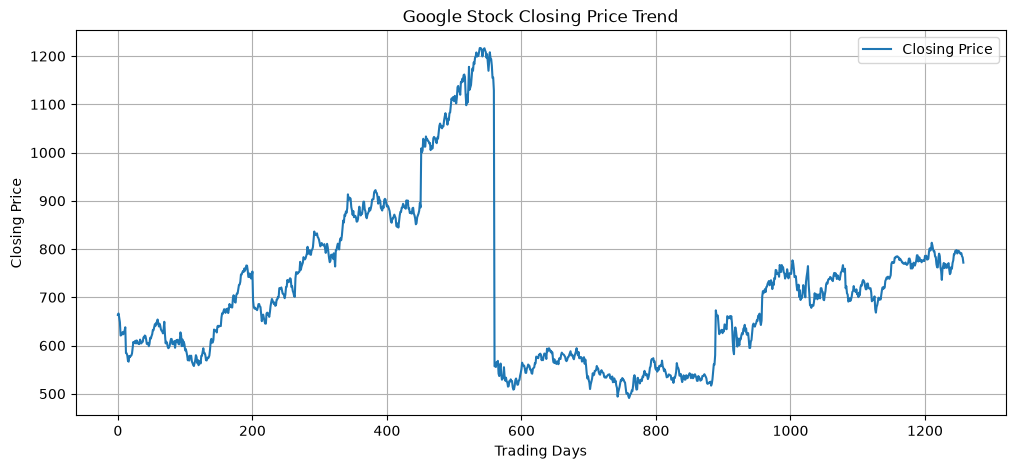

In [32]:
plt.figure(figsize=(12, 5))

plt.plot(train_data["Close"], label="Closing Price")

plt.title("Google Stock Closing Price Trend")
plt.xlabel("Trading Days")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)

plt.show()

### Closing Price Trend

The line plot shows how Google's closing stock price changed over the training period.

This visualization helps us understand the overall movement and fluctuations in the historical stock price.

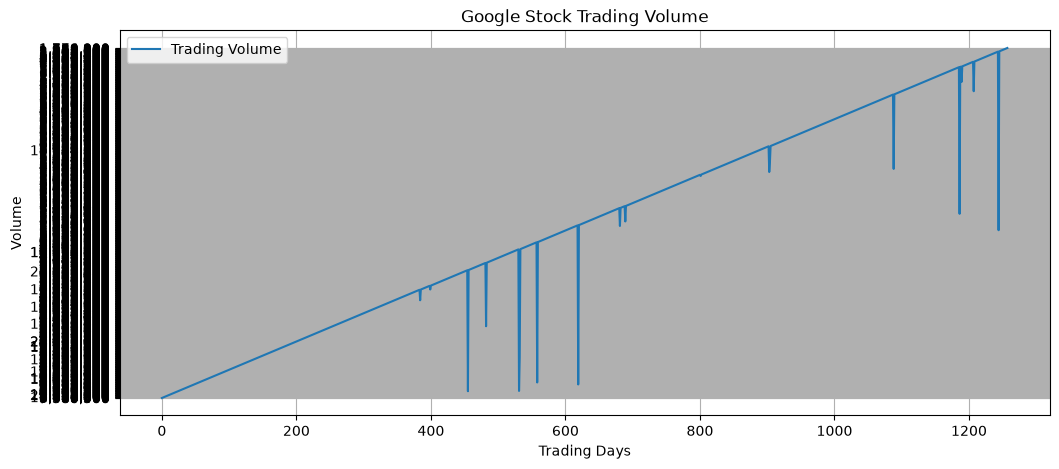

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(train_data["Volume"], label="Trading Volume")

plt.title("Google Stock Trading Volume")
plt.xlabel("Trading Days")
plt.ylabel("Volume")
plt.legend()
plt.grid(True)

plt.show()

### Trading Volume Analysis

The trading volume represents the number of shares traded during each trading period.

The plot helps identify variations in trading activity throughout the dataset.

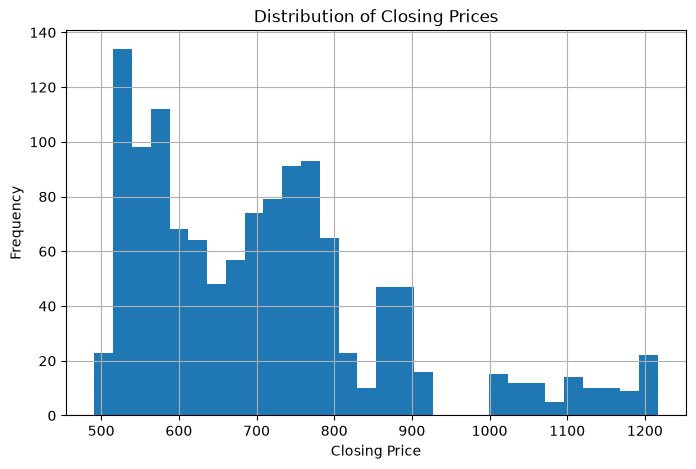

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(train_data["Close"], bins=30)

plt.title("Distribution of Closing Prices")
plt.xlabel("Closing Price")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

### Closing Price Distribution

The histogram shows the distribution of closing stock prices in the training dataset.

This helps us understand the range and frequency of different closing price values.

In [35]:
print("Minimum Closing Price:", train_data["Close"].min())
print("Maximum Closing Price:", train_data["Close"].max())
print("Mean Closing Price:", train_data["Close"].mean())
print("Median Closing Price:", train_data["Close"].median())

Minimum Closing Price: 491.2
Maximum Closing Price: 1216.83
Mean Closing Price: 712.6696661367249
Median Closing Price: 695.675


### EDA Summary

The EDA provides an understanding of the historical stock price trend, trading volume, and distribution of closing prices.

The identified patterns will be used as the basis for preparing the data for LSTM model training.

## 6. Feature Scaling Using MinMaxScaler

LSTM models perform better when numerical values are scaled to a common range.

In this step, the historical `Close` prices are normalized using `MinMaxScaler`.

The values are transformed into the range of 0 to 1. The scaler is fitted only on the training data to avoid data leakage.

In [15]:

# Create MinMaxScaler
scaler = MinMaxScaler(feature_range=(0, 1))

In [16]:
# Fit and transform training closing prices
scaled_training_data = scaler.fit_transform(training_close)

In [17]:
print("Original Close price:")
print(training_close[:5])

print("\nScaled Close price:")
print(scaled_training_data[:5])

Original Close price:
[[663.59]
 [666.45]
 [657.21]
 [648.24]
 [620.76]]

Scaled Close price:
[[0.23757287]
 [0.24151427]
 [0.22878051]
 [0.21641884]
 [0.1785483 ]]


### Scaling Result

The `Close` price values have been successfully transformed into the range of 0 to 1.

The fitted scaler will later be used to transform the test data and to convert the model's predictions back to the original stock price scale.

## 7. Creating Training Sequences

LSTM models require sequential input data because they are designed to learn patterns from time-series data.

In this step, we create sequences using the previous 60 trading days to predict the closing price of the next trading day.

Each training sample therefore contains:
- 60 previous closing-price values as input
- The next closing-price value as the target

In [18]:
# Number of previous trading days used to predict the next day
time_step = 60

X_train = []
y_train = []

for i in range(time_step, len(scaled_training_data)):
    X_train.append(scaled_training_data[i-time_step:i, 0])
    y_train.append(scaled_training_data[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (1198, 60)
y_train shape: (1198,)


In [19]:
X_train = np.reshape(
    X_train,
    (X_train.shape[0], X_train.shape[1], 1)
)

print("Final X_train shape:", X_train.shape)

Final X_train shape: (1198, 60, 1)


### Sequence Shape

The training data is reshaped into a three-dimensional format required by the LSTM model:

`[samples, time steps, features]`

In this project:

- Samples: 1198
- Time steps: 60
- Features: 1 (`Close` price)

Therefore, the final training input shape is `(1198, 60, 1)`.

### Sequence Creation Summary

The historical closing-price data has been converted into sequential training samples.

Each sample uses the previous 60 trading days to predict the next day's closing price. The data is now ready to be provided to the LSTM neural network.

## 8. Building the LSTM Model

Long Short-Term Memory (LSTM) is a type of Recurrent Neural Network (RNN) designed to learn patterns from sequential and time-series data.

In this project, an LSTM model is used to learn patterns from the historical Google stock closing prices.

The model consists of multiple LSTM layers, Dropout layers to reduce overfitting, and a Dense output layer to predict the next closing price.

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout


In [21]:
model = Sequential()

model.add(Input(shape=(X_train.shape[1], 1)))

model.add(
    LSTM(
        units=50,
        return_sequences=True,
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(
        units=50,
        return_sequences=True
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(units=50)
)

model.add(Dropout(0.2))

model.add(Dense(units=1))

model.summary()

c:\Users\admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 60, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 60, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

### Model Architecture

The LSTM model uses three LSTM layers with 50 units each.

Dropout layers with a rate of 20% are added between the LSTM layers to help reduce overfitting.

The final Dense layer contains one neuron because the model predicts a single value: the next day's closing stock price.

### Model Building Summary

The LSTM neural network has been successfully constructed and is ready for compilation and training.

## 9. Model Compilation and Training

Before training the LSTM model, the model is compiled using the Adam optimizer and Mean Squared Error (MSE) as the loss function.

The model is then trained using the prepared training sequences.

The training process allows the LSTM model to learn patterns from the historical closing stock prices.

In [22]:
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

print("Model compiled successfully!")

Model compiled successfully!


In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 75ms/step - loss: 0.0267
Epoch 2/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0083
Epoch 3/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0062
Epoch 4/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0083
Epoch 5/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0059
Epoch 6/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0052
Epoch 7/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - loss: 0.0050
Epoch 8/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 0.0045
Epoch 9/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - loss: 0.0045
Epoch 10/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0049
Epoch 11/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0039
Epoch 12/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - loss: 0.0043
Epoch 13/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 0.0042
Epoch 14/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - loss: 0.0037
Epoch 15/50
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 0.0039
Epo

### Training Loss

The training loss recorded during each epoch is stored in the `history` object.

A decreasing loss indicates that the model is learning patterns from the training data.

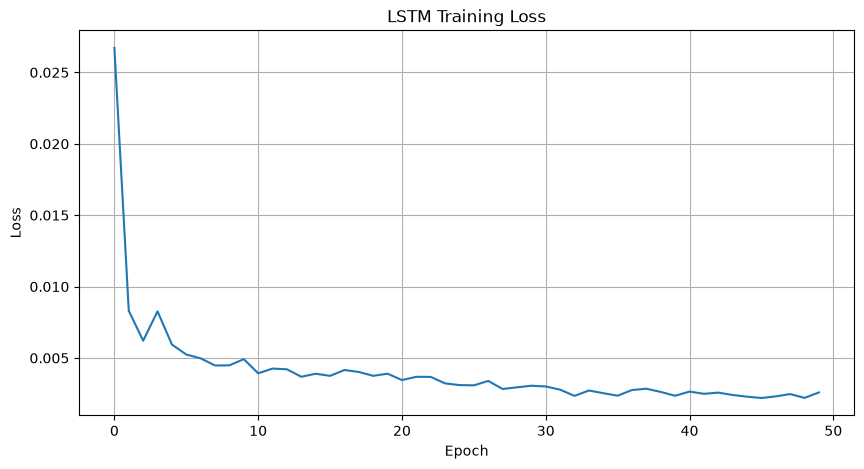

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"])

plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

In [25]:
from pathlib import Path
output_dir = Path.cwd() / 'outputs' / 'plots'
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / 'lstm_training_loss.png',
    dpi=300,
    bbox_inches='tight'
)


<Figure size 640x480 with 0 Axes>

### Training Summary

The LSTM model has been trained using 50 epochs and a batch size of 32.

The training loss curve is visualized to observe the model's learning behavior during training.

## 10. Test Data Preparation

The test dataset contains the actual Google stock closing prices for January 2017.

To make predictions for the test period, the model requires the previous 60 trading days as input.

Therefore, the last 60 observations from the training data are combined with the test data and scaled using the scaler fitted on the training data.

In [26]:
# Prepare test data for prediction

# Get actual closing prices from the test dataset
real_stock_price = test_data[["Close"]].values

# Combine training and test closing prices
total_data = pd.concat(
    [train_data[["Close"]], test_data[["Close"]]],
    axis=0
)

# Get the last 60 training observations
inputs = total_data[len(total_data) - len(test_data) - time_step:].values

# Reshape the input data
inputs = inputs.reshape(-1, 1)

# Apply the same scaler used during training
inputs_scaled = scaler.transform(inputs)

# Create test sequences
X_test = []

for i in range(time_step, time_step + len(test_data)):
    X_test.append(inputs_scaled[i-time_step:i, 0])

X_test = np.array(X_test)

# Reshape for LSTM
X_test = np.reshape(
    X_test,
    (X_test.shape[0], X_test.shape[1], 1)
)

print("X_test shape:", X_test.shape)

X_test shape: (20, 60, 1)


### Test Sequence Summary

The test data has been converted into the same three-dimensional structure used during training.

Each test sample contains the previous 60 trading days of closing prices.

The final test input shape is `(20, 60, 1)`, representing 20 test observations, 60 time steps, and 1 feature.

## 11. Making Predictions

In this step, the trained LSTM model is used to predict the closing stock prices for the test period.

The model generates predictions using the test sequences created in the previous step.

Since the model produces scaled values, the predictions are transformed back to the original stock price scale using the previously fitted MinMaxScaler.

In [27]:
predicted_stock_price_scaled = model.predict(X_test)

print("Prediction shape:", predicted_stock_price_scaled.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 509ms/step
Prediction shape: (20, 1)


In [28]:
predicted_stock_price = scaler.inverse_transform(
    predicted_stock_price_scaled
)

print("Predicted stock prices:")
print(predicted_stock_price[:5])

Predicted stock prices:
[[796.5135 ]
 [794.6673 ]
 [795.1858 ]
 [798.26465]
 [804.5248 ]]


### Prediction Summary

The prediction results contain the date, actual closing price, and LSTM-predicted closing price for each observation in the test dataset.

## 12. Model Evaluation

The performance of the LSTM model is evaluated by comparing the actual closing prices with the predicted closing prices.

Three evaluation metrics are used:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted values.
- **RMSE (Root Mean Squared Error):** Measures the square root of the average squared prediction error.
- **MAPE (Mean Absolute Percentage Error):** Measures the average percentage difference between actual and predicted values.

These metrics help quantify the prediction error of the LSTM model on the test dataset.

In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(
    real_stock_price,
    predicted_stock_price
)

rmse = np.sqrt(
    mean_squared_error(
        real_stock_price,
        predicted_stock_price
    )
)

mape = np.mean(
    np.abs(
        (real_stock_price - predicted_stock_price)
        / real_stock_price
    )
) * 100

print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

MAE : 12.853053710937502
RMSE: 17.07467124870173
MAPE: 1.5969532939693414 %


### Evaluation Results

The calculated evaluation metrics provide a quantitative measure of the LSTM model's prediction performance on the January 2017 test dataset.

Lower error values indicate a smaller difference between the actual and predicted stock prices.

## 13. Actual vs Predicted Stock Price – January 2017

In this step, the actual closing stock prices are compared with the closing prices predicted by the LSTM model.

The comparison is visualized using a line plot for the January 2017 test period.

This visualization helps us understand how closely the model's predictions follow the actual stock price movement.

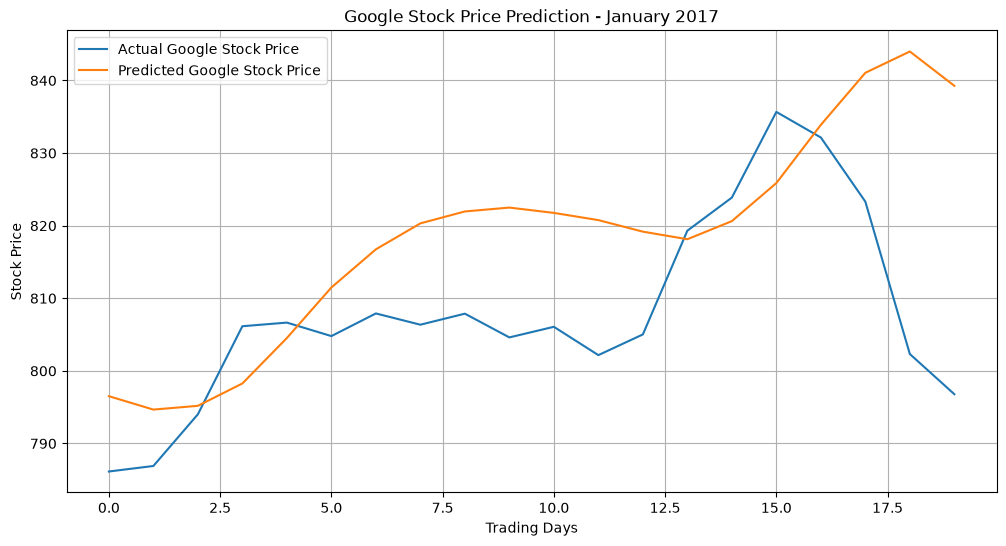

In [29]:
plt.figure(figsize=(12, 6))

plt.plot(
    real_stock_price,
    label="Actual Google Stock Price"
)

plt.plot(
    predicted_stock_price,
    label="Predicted Google Stock Price"
)

plt.title("Google Stock Price Prediction - January 2017")
plt.xlabel("Trading Days")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)

plt.show()

In [39]:
results = pd.DataFrame({
    "Date": test_data["Date"],
    "Actual_Close": real_stock_price.flatten(),
    "Predicted_Close": predicted_stock_price.flatten()
})

results

,Date,Actual_Close,Predicted_Close
0,1/3/2017,786.14,796.513489
1,1/4/2017,786.90,794.667297
2,1/5/2017,794.02,795.185791
3,1/6/2017,806.15,798.264648
4,1/9/2017,806.65,804.524780
5,1/10/2017,804.79,811.485596
6,1/11/2017,807.91,816.741089
7,1/12/2017,806.36,820.318176
8,1/13/2017,807.88,821.959290
9,1/17/2017,804.61,822.492737


### Visualization Summary

The plot compares the actual and predicted Google stock closing prices for January 2017.

The difference between the two lines represents the prediction error of the LSTM model during the test period.

## 14. Results and Conclusion

### Model Results

The LSTM model was trained on historical Google stock closing prices and evaluated on the January 2017 test dataset.

The model was trained using 50 epochs with a batch size of 32 and used the previous 60 trading days to predict the next day's closing price.

The final evaluation results are:

| Evaluation Metric | Result |
|---|---:|
| MAE | 12.8531 |
| RMSE | 17.0747 |
| MAPE | 1.60% |

The model achieved a Mean Absolute Error (MAE) of approximately 12.85 and a Root Mean Squared Error (RMSE) of approximately 17.07 on the test dataset. The Mean Absolute Percentage Error (MAPE) was approximately 1.60%.

### Conclusion

This project demonstrates the application of Long Short-Term Memory (LSTM), a type of Recurrent Neural Network, for time-series stock price prediction.

The historical stock data was loaded, understood, cleaned, and explored through Exploratory Data Analysis. The closing price was selected as the target variable and normalized using MinMaxScaler.

The scaled data was converted into sequences using 60 previous trading days as input. An LSTM model with multiple LSTM and Dropout layers was then trained using the prepared sequences.

The trained model was tested on the January 2017 dataset. The predicted stock prices were converted back to the original price scale and compared with the actual closing prices using MAE, RMSE, MAPE, and an Actual vs Predicted visualization.

The results show that the developed LSTM model was able to learn patterns from the historical training data and generate predictions for the test period. The evaluation metrics provide a quantitative measure of the model's prediction error.

This project provides a practical implementation of deep learning for stock market time-series analysis and demonstrates the complete workflow from data preprocessing to model evaluation.